In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/raw/creditcard.csv")

print("File exists:", data_path.exists())

df = pd.read_csv(data_path)
print("Rows and columns:", df.shape)
display(df.head())

File exists: True
Rows and columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

quality = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

display(quality)
print("Exact duplicate rows:", df.duplicated().sum())

Rows and columns: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,data_type,missing_values,missing_percent
Time,float64,0,0.0
V1,float64,0,0.0
V2,float64,0,0.0
V3,float64,0,0.0
V4,float64,0,0.0
V5,float64,0,0.0
V6,float64,0,0.0
V7,float64,0,0.0
V8,float64,0,0.0
V9,float64,0,0.0


Exact duplicate rows: 1081


In [3]:
print("Class values:")
display(df["Class"].value_counts(dropna=False))

class_summary = pd.DataFrame({
    "count": df["Class"].value_counts().sort_index(),
    "percentage": (
        df["Class"].value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(4)
    )
})

display(class_summary)

Class values:


Class
0    284315
1       492
Name: count, dtype: int64

,count,percentage
Class,,
0,284315,99.8273
1,492,0.1727


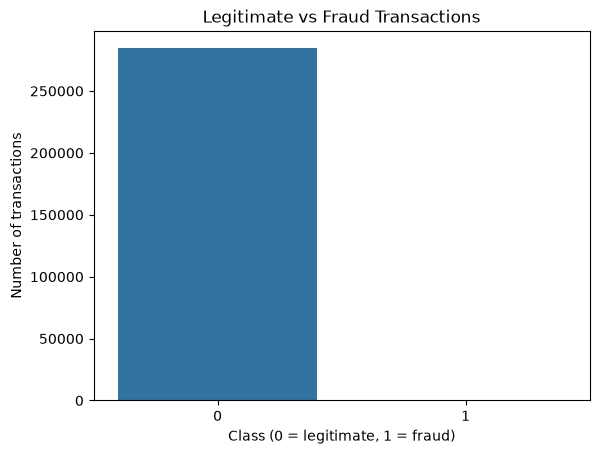

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraud Transactions")
plt.xlabel("Class (0 = legitimate, 1 = fraud)")
plt.ylabel("Number of transactions")
plt.show()

In [5]:
display(
    df.groupby("Class")[["Amount", "Time"]]
      .agg(["count", "mean", "median", "max"])
      .round(2)
)

Amount                             Time                             
        count    mean median       max   count      mean   median       max
Class                                                                      
0      284315   88.29  22.00  25691.16  284315  94838.20  84711.0  172792.0
1         492  122.21   9.25   2125.87     492  80746.81  75568.5  170348.0

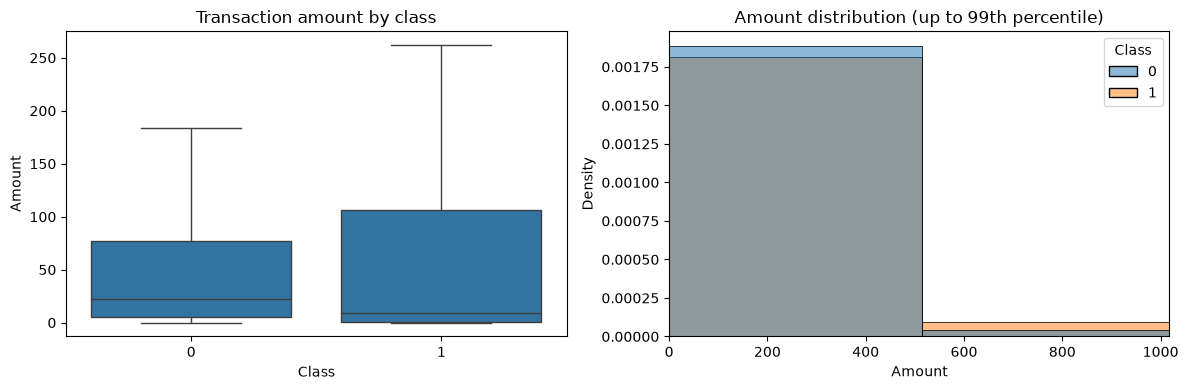

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Class", y="Amount", showfliers=False, ax=axes[0])
axes[0].set_title("Transaction amount by class")

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False,
    ax=axes[1]
)
axes[1].set_xlim(0, df["Amount"].quantile(0.99))
axes[1].set_title("Amount distribution (up to 99th percentile)")

plt.tight_layout()
plt.show()